<a href="https://colab.research.google.com/github/danielshikuku/Hypertension-Risk-Analytics/blob/main/hypertension.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

I imported pandas as pd to import and clean the dataset that I was going to analyze with DataFrames and numpy as np for numerical manipulation and handling missing values.I also imported matplotlib.pyplot as plt because I wanted to create static graphs with raw control over figure size, axes and labels.In addition, I imported chart_studio.plotly, which enabled me to post interactive plotly charts, I used seaborn to beautiful statistical charts with much simpler code, and plotly.express to create highly interactive charts with single-line code.From scipy import stats I could conduct a massive normality check, from sklearn.impute import SimpleImputer to fill the blanks (NaNs) in my data with various methods such as column-wise mean, median or mode, while from sklearn.compose import ColumnTransformer enabled me to apply different preprocessing steps to different columns simultaneously, and from sklearn.linear_model import LinearRegression, to train on my preprocessed data to see if there is a linear relationship between independent and dependent variables, and predict continuous numerical data.

In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

1st I cloned my hypertension risk analysis to github to enable me commit changes with much ease and  then loaded my Dataset and finally ran a few codes to know the general information for better understanding.

In [112]:

username = "danielshikuku"
repo = "Hypertension-Risk-Analytics"

!git clone https://github.com/{username}/{repo}.git
%cd {repo}
%ls

Cloning into 'Hypertension-Risk-Analytics'...
remote: Enumerating objects: 40, done.
remote: Counting objects: 100% (40/40), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 40 (delta 15), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (40/40), 545.02 KiB | 6.49 MiB/s, done.
Resolving deltas: 100% (15/15), done.
/content/Hypertension-Risk-Analytics/Hypertension-Risk-Analytics/Hypertension-Risk-Analytics
cleaned_hypertension_dataset_5000.csv  hypertension.ipynb
hypertension_dataset_5000.csv


In [113]:
df = pd.read_csv("hypertension_dataset_5000.csv")

In [114]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     5000 non-null   float64
 1   Gender                  5000 non-null   object 
 2   BMI                     5000 non-null   float64
 3   Waist_Circumference_cm  4846 non-null   float64
 4   Salt_Intake             4939 non-null   object 
 5   Physical_Activity       5000 non-null   object 
 6   Alcohol_Consumption     3632 non-null   object 
 7   Smoking_Status          5000 non-null   object 
 8   Stress_Level            4909 non-null   object 
 9   Sleep_Hours             4837 non-null   float64
 10  Family_History_HTN      5000 non-null   object 
 11  Creatinine_mg_dL        4867 non-null   float64
 12  Fasting_Glucose_mg_dL   4821 non-null   float64
 13  Cholesterol_mg_dL       4841 non-null   float64
 14  Systolic_BP_mmHg        5000 non-null   

In [115]:
df.head()

,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension
0,83.2,Male,24.6,92.5,Normal,Light,NaN,Former,Moderate,7.5,No,0.98,89.0,201.4,119,65,Normal,No
1,69.0,Female,26.1,76.6,Very High,Light,NaN,Former,Low,6.5,Yes,NaN,83.2,178.9,132,81,Stage 1 Hypertension,Yes
2,45.1,Male,24.5,86.4,High,Sedentary,Occasional,Former,Very High,6.1,No,1.02,86.0,163.2,131,87,Stage 1 Hypertension,Yes
3,45.5,Male,25.6,85.2,Normal,Active,Moderate,Current,High,6.4,Yes,0.86,80.5,146.0,127,88,Stage 1 Hypertension,Yes
4,41.7,Male,28.7,97.4,High,Active,Moderate,Current,High,6.9,No,1.27,97.0,210.6,120,78,Elevated,No


In [116]:
df.tail()

,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension
4995,33.2,Male,26.4,82.6,Normal,Light,Heavy,Never,High,7.8,No,0.96,78.9,230.6,125,87,Stage 1 Hypertension,Yes
4996,40.0,Male,26.4,84.0,Low,Light,NaN,Former,Moderate,8.2,Yes,NaN,108.7,175.9,131,73,Stage 1 Hypertension,Yes
4997,38.5,Female,35.1,NaN,High,Sedentary,Occasional,Former,Moderate,6.5,Yes,0.74,83.7,178.3,141,86,Stage 2 Hypertension,Yes
4998,26.2,Female,25.4,71.9,High,Sedentary,Occasional,Current,Very High,7.4,Yes,0.72,127.9,NaN,129,74,Elevated,No
4999,20.9,Female,16.3,56.7,Very High,Active,NaN,Never,Moderate,7.4,Yes,0.78,NaN,152.4,97,63,Normal,No


In [117]:
df.shape

(5000, 18)

In [118]:
df.describe(include="all")

,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension
count,5000.000000,5000,5000.000000,4846.000000,4939,5000,3632,5000,4909,4837.000000,5000,4867.000000,4821.000000,4841.000000,5000.000000,5000.000000,5000,5000
unique,NaN,2,NaN,NaN,4,4,3,3,4,NaN,2,NaN,NaN,NaN,NaN,NaN,4,2
top,NaN,Female,NaN,NaN,Normal,Light,Occasional,Never,Moderate,NaN,No,NaN,NaN,NaN,NaN,NaN,Normal,No
freq,NaN,2581,NaN,NaN,1696,1678,1910,2805,1844,NaN,3218,NaN,NaN,NaN,NaN,NaN,2713,3250
mean,48.648320,NaN,27.876320,89.417623,NaN,NaN,NaN,NaN,NaN,6.850444,NaN,0.942063,93.301058,187.219851,116.826600,74.259600,NaN,NaN
std,16.908037,NaN,4.254628,11.410790,NaN,NaN,NaN,NaN,NaN,1.042016,NaN,0.171618,12.753358,30.546704,16.385269,9.483849,NaN,NaN
min,18.200000,NaN,16.200000,54.000000,NaN,NaN,NaN,NaN,NaN,3.500000,NaN,0.510000,62.100000,105.000000,88.000000,50.000000,NaN,NaN
25%,34.575000,NaN,24.900000,81.500000,NaN,NaN,NaN,NaN,NaN,6.200000,NaN,0.820000,84.500000,165.600000,104.000000,67.000000,NaN,NaN
50%,47.400000,NaN,27.700000,89.100000,NaN,NaN,NaN,NaN,NaN,6.900000,NaN,0.930000,92.200000,187.300000,115.000000,74.000000,NaN,NaN
75%,61.600000,NaN,30.800000,97.100000,NaN,NaN,NaN,NaN,NaN,7.500000,NaN,1.050000,100.900000,207.600000,128.000000,81.000000,NaN,NaN


In [119]:
df.dtypes.value_counts()

,count
object,9
float64,7
int64,2


In [120]:
df.columns

Index(['Age', 'Gender', 'BMI', 'Waist_Circumference_cm', 'Salt_Intake',
       'Physical_Activity', 'Alcohol_Consumption', 'Smoking_Status',
       'Stress_Level', 'Sleep_Hours', 'Family_History_HTN', 'Creatinine_mg_dL',
       'Fasting_Glucose_mg_dL', 'Cholesterol_mg_dL', 'Systolic_BP_mmHg',
       'Diastolic_BP_mmHg', 'BP_Category', 'Hypertension'],
      dtype='object')

2nd I had to check missing values just to understand the scope of the raw data

In [121]:
pd.DataFrame({'dtype':df.dtypes.astype(str),'unique':df.nunique(),'missing':df.isnull().sum()})


,dtype,unique,missing
Age,float64,681,0
Gender,object,2,0
BMI,float64,245,0
Waist_Circumference_cm,float64,578,154
Salt_Intake,object,4,61
Physical_Activity,object,4,0
Alcohol_Consumption,object,3,1368
Smoking_Status,object,3,0
Stress_Level,object,4,91
Sleep_Hours,float64,68,163


3rd Handle missing values from the 8 columns

1) I started by first fixing the missing values of "alcohol_consuption"

In [122]:
df["Alcohol_Consumption"] = df["Alcohol_Consumption"].fillna("Unknown")
print(df["Alcohol_Consumption"].isna().sum())

0


2) I continued by fixing missing value "salt_intake"

In [123]:
df["Salt_Intake"] = df["Salt_Intake"].fillna(df["Salt_Intake"].mode()[0])
print(df["Salt_Intake"].isna().sum())

0


3) I fixed missing value "sleeping_hours"

In [124]:
df['Sleep_Hours'] = df['Sleep_Hours'].fillna(df['Sleep_Hours'].median())
print(df["Sleep_Hours"].isna().sum())

0


4) I continued by fixing missing value "Waist_Circumference_cm"

In [125]:
df['Waist_Circumference_cm'] = df['Waist_Circumference_cm'].fillna(df['Waist_Circumference_cm'].median())
print(df["Waist_Circumference_cm"].isna().sum())

0


5) I then fixed missing value "stress_level"

In [126]:
df["Stress_Level"] = df["Stress_Level"].fillna(df["Stress_Level"].mode()[0])
print(df["Stress_Level"].isna().sum())

0


6) I continued by fixing missing value "Creatinine_mg_dL"


In [127]:
df['Creatinine_mg_dL'] = df['Creatinine_mg_dL'].fillna(df['Creatinine_mg_dL'].median())
print(df['Creatinine_mg_dL'].isna().sum())

0


7) I fixed missing value "Cholesterol_mg_dL"

In [128]:
df['Cholesterol_mg_dL'] = df['Cholesterol_mg_dL'].fillna(df['Cholesterol_mg_dL'].median())
print(df['Cholesterol_mg_dL'].isna().sum())

0


8) I finally fixed missing value "Fasting_Glucose_mg_dm"

In [129]:
df['Fasting_Glucose_mg_dL'] = df['Fasting_Glucose_mg_dL'].fillna(df['Fasting_Glucose_mg_dL'].median())
print(df['Fasting_Glucose_mg_dL'].isna().sum())

0


I again ran the code to check any other missing value after handling

In [130]:
pd.DataFrame({'dtype':df.dtypes.astype(str),'unique':df.nunique(),'missing':df.isnull().sum()})

,dtype,unique,missing
Age,float64,681,0
Gender,object,2,0
BMI,float64,245,0
Waist_Circumference_cm,float64,578,0
Salt_Intake,object,4,0
Physical_Activity,object,4,0
Alcohol_Consumption,object,4,0
Smoking_Status,object,3,0
Stress_Level,object,4,0
Sleep_Hours,float64,68,0


In [131]:
print(df.isnull().sum())

Age                       0
Gender                    0
BMI                       0
Waist_Circumference_cm    0
Salt_Intake               0
Physical_Activity         0
Alcohol_Consumption       0
Smoking_Status            0
Stress_Level              0
Sleep_Hours               0
Family_History_HTN        0
Creatinine_mg_dL          0
Fasting_Glucose_mg_dL     0
Cholesterol_mg_dL         0
Systolic_BP_mmHg          0
Diastolic_BP_mmHg         0
BP_Category               0
Hypertension              0
dtype: int64


4th Removing duplicate from my dataset

In [132]:
df.duplicated().sum()

np.int64(0)

In [133]:
df.dtypes

,0
Age,float64
Gender,object
BMI,float64
Waist_Circumference_cm,float64
Salt_Intake,object
Physical_Activity,object
Alcohol_Consumption,object
Smoking_Status,object
Stress_Level,object
Sleep_Hours,float64


5th Since there was no duplicate I proceded to check category data

Identify which categories are treated as text or categories

In [134]:
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
print("Categorical Columns:", list(categorical_cols))

Categorical Columns: ['Gender', 'Salt_Intake', 'Physical_Activity', 'Alcohol_Consumption', 'Smoking_Status', 'Stress_Level', 'Family_History_HTN', 'BP_Category', 'Hypertension']


Check unique values and search for typos in 1st 10 columns

In [135]:
for col in categorical_cols:
    print(f"\n--- Unique values in '{col}' (Top 10) ---")
    print(df[col].value_counts(dropna=False).head(10))


--- Unique values in 'Gender' (Top 10) ---
Gender
Female    2581
Male      2419
Name: count, dtype: int64

--- Unique values in 'Salt_Intake' (Top 10) ---
Salt_Intake
Normal       1757
High         1597
Very High    1011
Low           635
Name: count, dtype: int64

--- Unique values in 'Physical_Activity' (Top 10) ---
Physical_Activity
Light        1678
Sedentary    1327
Moderate     1258
Active        737
Name: count, dtype: int64

--- Unique values in 'Alcohol_Consumption' (Top 10) ---
Alcohol_Consumption
Occasional    1910
Unknown       1368
Moderate      1231
Heavy          491
Name: count, dtype: int64

--- Unique values in 'Smoking_Status' (Top 10) ---
Smoking_Status
Never      2805
Former     1440
Current     755
Name: count, dtype: int64

--- Unique values in 'Stress_Level' (Top 10) ---
Stress_Level
Moderate     1935
High         1410
Low           844
Very High     811
Name: count, dtype: int64

--- Unique values in 'Family_History_HTN' (Top 10) ---
Family_History_HTN
No     

Check for structural anomalies

In [136]:
for col in categorical_cols:
    has_whitespace = df[col].astype(str).str.contains(r'^\s|\s$').any()
    has_mixed_case = df[col].dropna().nunique() != df[col].dropna().str.lower().nunique()
    if has_whitespace or has_mixed_case:
        print(f"Column '{col}' needs cleaning (Whitespace: {has_whitespace}, Mixed Case: {has_mixed_case})")

Check cardinality (High cardinality text columns shouldn't be cast as 'category')

In [137]:
print("\n--- Cardinality Check ---")
print(df[categorical_cols].nunique())


--- Cardinality Check ---
Gender                 2
Salt_Intake            4
Physical_Activity      4
Alcohol_Consumption    4
Smoking_Status         3
Stress_Level           4
Family_History_HTN     2
BP_Category            4
Hypertension           2
dtype: int64


In [138]:
print(df.columns.tolist())

['Age', 'Gender', 'BMI', 'Waist_Circumference_cm', 'Salt_Intake', 'Physical_Activity', 'Alcohol_Consumption', 'Smoking_Status', 'Stress_Level', 'Sleep_Hours', 'Family_History_HTN', 'Creatinine_mg_dL', 'Fasting_Glucose_mg_dL', 'Cholesterol_mg_dL', 'Systolic_BP_mmHg', 'Diastolic_BP_mmHg', 'BP_Category', 'Hypertension']


6th Checked for outliers and invalid values

 checking using loops

In [139]:
numeric_columns = df.select_dtypes(include=np.number).columns
for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(col, ":", len(outliers), "outliers")

Age : 0 outliers
BMI : 23 outliers
Waist_Circumference_cm : 33 outliers
Sleep_Hours : 57 outliers
Creatinine_mg_dL : 39 outliers
Fasting_Glucose_mg_dL : 94 outliers
Cholesterol_mg_dL : 21 outliers
Systolic_BP_mmHg : 22 outliers
Diastolic_BP_mmHg : 11 outliers


A boxplot helps you visually identify outliers

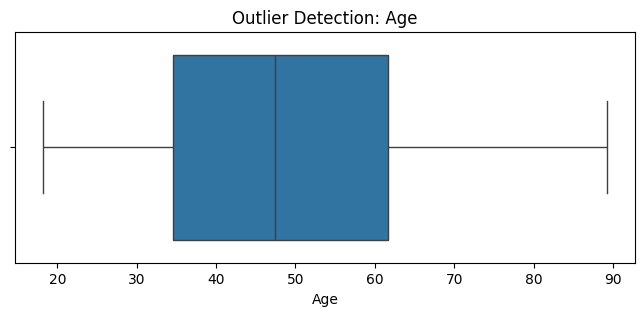

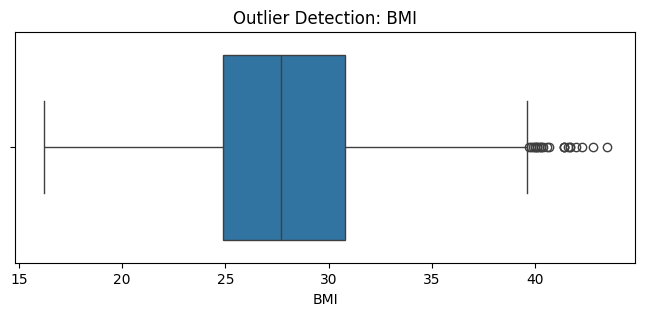

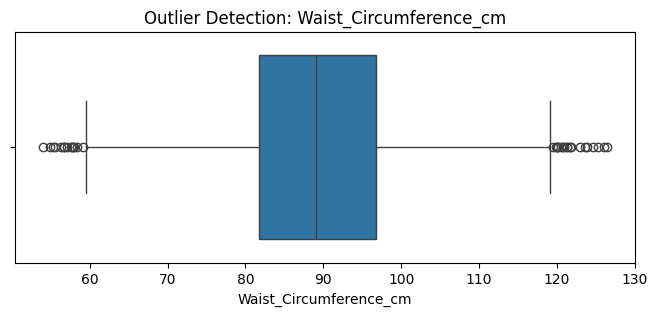

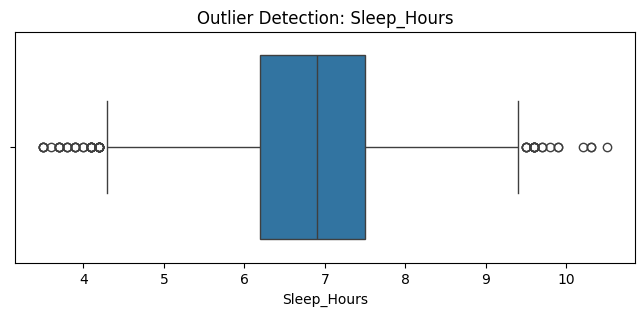

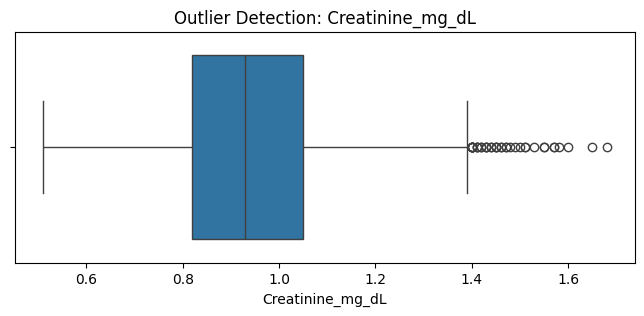

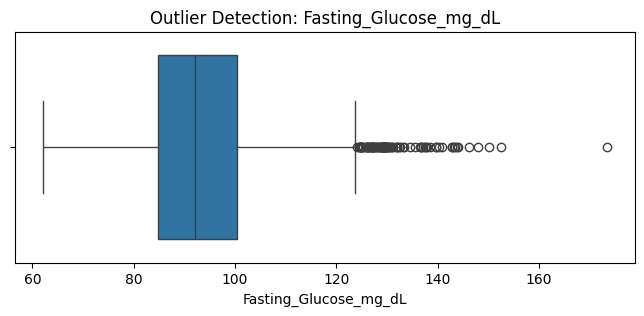

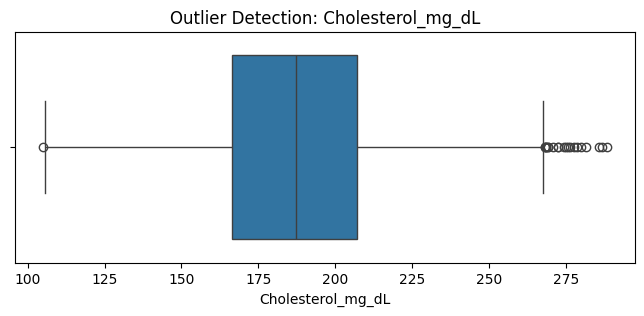

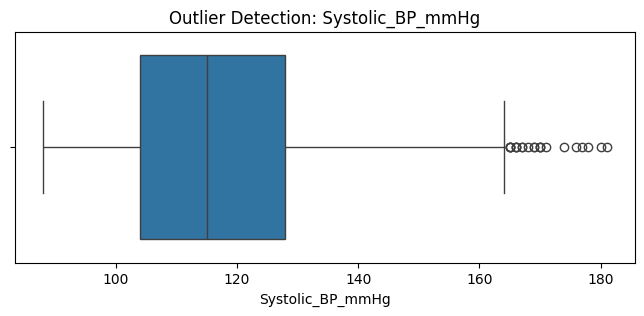

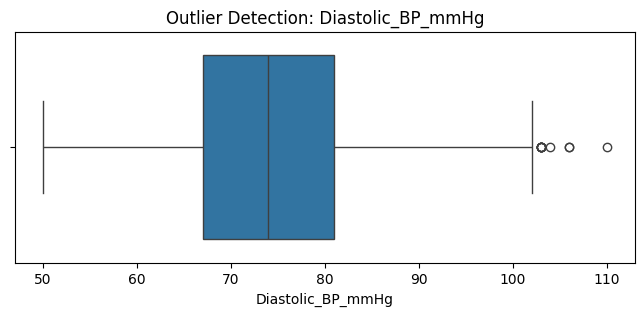

In [140]:
numeric_columns = [
    "Age",
    "BMI",
    "Waist_Circumference_cm",
    "Sleep_Hours",
    "Creatinine_mg_dL",
    "Fasting_Glucose_mg_dL",
    "Cholesterol_mg_dL",
    "Systolic_BP_mmHg",
    "Diastolic_BP_mmHg"
]

for col in numeric_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Detection: {col}")
    plt.show()

check for invalid value

In [141]:
print("Invalid Age:")
display(df[df["Age"] < 0])

print("Invalid BMI:")
display(df[df["BMI"] <= 0])

print("Invalid Waist Circumference:")
display(df[df["Waist_Circumference_cm"] <= 0])

print("Invalid Glucose:")
display(df[df["Fasting_Glucose_mg_dL"] < 0])

print("Invalid Cholesterol:")
display(df[df["Cholesterol_mg_dL"] < 0])

Invalid Age:


,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension


Invalid BMI:


,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension


Invalid Waist Circumference:


,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension


Invalid Glucose:


,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension


Invalid Cholesterol:


,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension


7th Created a new column ie feature engineering

1st column age_band(age): 'Under 30', '30-44', '45-59', '60+'

In [142]:
def age_band(age):
    if age < 30:
        return 'Under 30'
    elif age < 45:
        return '30-44'
    elif age < 60:
        return '45-59'
    else:
        return '60+'

df['Age_band'] = df['Age'].apply(age_band)
df['Age_band'].value_counts()

,count
Age_band,
30-44,1462
60+,1393
45-59,1339
Under 30,806


2nd column bmi_group(bmi): under 18.5 'Underweight', under 25 'Normal', under 30 'Overweight', otherwise 'Obese'.

In [143]:
def bmi_Group(bmi):
    if bmi < 18.5:
        return 'Underweight'
    elif bmi < 25:
        return 'Normal'
    elif bmi < 30:
        return 'Overweight'
    else:
        return 'Obese'

df['BMI_Group'] = df['BMI'].apply(bmi_Group)
print(df['BMI_Group'].value_counts())

BMI_Group
Overweight     2195
Obese          1542
Normal         1223
Underweight      40
Name: count, dtype: int64


3rd Blood Pressure Status

In [144]:
def bp_status(systolic, diastolic):
    if pd.isna(systolic) or pd.isna(diastolic):
        return "Unknown"
    elif systolic >= 140 or diastolic >= 90:
        return "High"
    elif systolic >= 120 or diastolic >= 80:
        return "Elevated"
    else:
        return "Normal"

df["BP_Status"] = df.apply(lambda row: bp_status(row["Systolic_BP_mmHg"],row["Diastolic_BP_mmHg"]),axis=1)
print(df[["Systolic_BP_mmHg", "Diastolic_BP_mmHg", "BP_Status"]].head(10))
print(df["BP_Status"].value_counts())

   Systolic_BP_mmHg  Diastolic_BP_mmHg BP_Status
0               119                 65    Normal
1               132                 81  Elevated
2               131                 87  Elevated
3               127                 88  Elevated
4               120                 78  Elevated
5               112                 78    Normal
6               113                 71    Normal
7               126                 91      High
8               131                 89  Elevated
9                99                 69    Normal
BP_Status
Normal      2713
Elevated    1684
High         603
Name: count, dtype: int64


4th Sleeping status

In [145]:

def sleep_category(hours):
    if pd.isna(hours):
        return "Unknown"
    elif hours < 7:
        return "Short Sleep"
    elif hours < 9:
        return "Normal Sleep"
    else:
        return "Long Sleep"
df["Sleep_Category"] = df["Sleep_Hours"].apply(sleep_category)
print(df[["Sleep_Hours", "Sleep_Category"]].head(10))
print(df["Sleep_Category"].value_counts())

   Sleep_Hours Sleep_Category
0          7.5   Normal Sleep
1          6.5    Short Sleep
2          6.1    Short Sleep
3          6.4    Short Sleep
4          6.9    Short Sleep
5          6.9    Short Sleep
6          6.7    Short Sleep
7          5.5    Short Sleep
8          7.6   Normal Sleep
9          7.2   Normal Sleep
Sleep_Category
Short Sleep     2772
Normal Sleep    2135
Long Sleep        93
Name: count, dtype: int64


5th Stress

In [146]:
def stress_category(stress):
    if pd.isna(stress):
        return "Unknown"
    elif stress == "Low":
        return "Low Stress"
    elif stress == "Moderate":
        return "Moderate Stress"
    elif stress == "High":
        return "High Stress"
    elif stress == "Very High":
        return "Very High Stress"
    else:
        return "Unknown"
df["Stress_Category"] = df["Stress_Level"].apply(stress_category)
print(df[["Stress_Level", "Stress_Category"]].head(10))
print(df["Stress_Category"].value_counts())

  Stress_Level   Stress_Category
0     Moderate   Moderate Stress
1          Low        Low Stress
2    Very High  Very High Stress
3         High       High Stress
4         High       High Stress
5         High       High Stress
6         High       High Stress
7         High       High Stress
8     Moderate   Moderate Stress
9         High       High Stress
Stress_Category
Moderate Stress     1935
High Stress         1410
Low Stress           844
Very High Stress     811
Name: count, dtype: int64


6th Salt intake

In [147]:
def salt_category(salt):
    if pd.isna(salt):
        return "Unknown"
    elif salt == "Low":
        return "Low Salt"
    elif salt == "Normal":
        return "Normal Salt"
    elif salt == "High":
        return "High Salt"
    elif salt == "Very High":
        return "Very High Salt"
    else:
        return "Unknown"

df["Salt_Category"] = df["Salt_Intake"].apply(salt_category)

print(df[["Salt_Intake", "Salt_Category"]].head(10))
print(df["Salt_Category"].value_counts())

  Salt_Intake   Salt_Category
0      Normal     Normal Salt
1   Very High  Very High Salt
2        High       High Salt
3      Normal     Normal Salt
4        High       High Salt
5        High       High Salt
6        High       High Salt
7   Very High  Very High Salt
8   Very High  Very High Salt
9        High       High Salt
Salt_Category
Normal Salt       1757
High Salt         1597
Very High Salt    1011
Low Salt           635
Name: count, dtype: int64


7th Systolic_Category

In [148]:
def systolic_category(systolic):
    if pd.isna(systolic):
        return "Unknown"
    elif systolic >= 140:
        return "High"
    elif systolic >= 120:
        return "Elevated"
    else:
        return "Normal"

df["Systolic_Category"] = df["Systolic_BP_mmHg"].apply(systolic_category)

print(df[["Systolic_BP_mmHg", "Systolic_Category"]].head(10))
print(df["Systolic_Category"].value_counts())

   Systolic_BP_mmHg Systolic_Category
0               119            Normal
1               132          Elevated
2               131          Elevated
3               127          Elevated
4               120          Elevated
5               112            Normal
6               113            Normal
7               126          Elevated
8               131          Elevated
9                99            Normal
Systolic_Category
Normal      2982
Elevated    1518
High         500
Name: count, dtype: int64


8th Diastolic_Category

In [149]:
def diastolic_category(diastolic):
    if pd.isna(diastolic):
        return "Unknown"
    elif diastolic >= 90:
        return "High"
    elif diastolic >= 80:
        return "Elevated"
    else:
        return "Normal"

df["Diastolic_Category"] = df["Diastolic_BP_mmHg"].apply(diastolic_category)

print(df[["Diastolic_BP_mmHg", "Diastolic_Category"]].head(10))
print(df["Diastolic_Category"].value_counts())

   Diastolic_BP_mmHg Diastolic_Category
0                 65             Normal
1                 81           Elevated
2                 87           Elevated
3                 88           Elevated
4                 78             Normal
5                 78             Normal
6                 71             Normal
7                 91               High
8                 89           Elevated
9                 69             Normal
Diastolic_Category
Normal      3533
Elevated    1155
High         312
Name: count, dtype: int64


8th Verifying the data is clean for analysis

In [150]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [151]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


Check invalid values

In [152]:
print("Invalid Waist:",
      (df["Waist_Circumference_cm"] <= 0).sum())

print("Invalid Glucose:",
      (df["Fasting_Glucose_mg_dL"] < 0).sum())

print("Invalid Cholesterol:",
      (df["Cholesterol_mg_dL"] < 0).sum())

print("Invalid Systolic BP:",
      (df["Systolic_BP_mmHg"] <= 0).sum())

print("Invalid Diastolic BP:",
      (df["Diastolic_BP_mmHg"] <= 0).sum())

Invalid Waist: 0
Invalid Glucose: 0
Invalid Cholesterol: 0
Invalid Systolic BP: 0
Invalid Diastolic BP: 0


Check categorical values

In [153]:
categorical_columns = [
    "Gender",
    "Stress_Level",
    "Salt_Intake",
    "Physical_Activity",
    "Alcohol_Consumption",
    "Smoking_Status",
    "Family_History_HTN",
    "BP_Category",
    "Hypertension"
]

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts(dropna=False))


 Gender
Gender
Female    2581
Male      2419
Name: count, dtype: int64

 Stress_Level
Stress_Level
Moderate     1935
High         1410
Low           844
Very High     811
Name: count, dtype: int64

 Salt_Intake
Salt_Intake
Normal       1757
High         1597
Very High    1011
Low           635
Name: count, dtype: int64

 Physical_Activity
Physical_Activity
Light        1678
Sedentary    1327
Moderate     1258
Active        737
Name: count, dtype: int64

 Alcohol_Consumption
Alcohol_Consumption
Occasional    1910
Unknown       1368
Moderate      1231
Heavy          491
Name: count, dtype: int64

 Smoking_Status
Smoking_Status
Never      2805
Former     1440
Current     755
Name: count, dtype: int64

 Family_History_HTN
Family_History_HTN
No     3218
Yes    1782
Name: count, dtype: int64

 BP_Category
BP_Category
Normal                  2713
Stage 1 Hypertension    1147
Stage 2 Hypertension     603
Elevated                 537
Name: count, dtype: int64

 Hypertension
Hypertension
No    

Check newly created columns

In [154]:
new_columns = [
    "BMI_Group",
    "BP_Status",
    "Sleep_Category",
    "Stress_Category",
    "Salt_Category"
]

for col in new_columns:
    if col in df.columns:
        print("\n", col)
        print(df[col].value_counts(dropna=False))


 BMI_Group
BMI_Group
Overweight     2195
Obese          1542
Normal         1223
Underweight      40
Name: count, dtype: int64

 BP_Status
BP_Status
Normal      2713
Elevated    1684
High         603
Name: count, dtype: int64

 Sleep_Category
Sleep_Category
Short Sleep     2772
Normal Sleep    2135
Long Sleep        93
Name: count, dtype: int64

 Stress_Category
Stress_Category
Moderate Stress     1935
High Stress         1410
Low Stress           844
Very High Stress     811
Name: count, dtype: int64

 Salt_Category
Salt_Category
Normal Salt       1757
High Salt         1597
Very High Salt    1011
Low Salt           635
Name: count, dtype: int64


In [155]:
print("DATA VALIDATION SUMMARY")

print("Dataset shape:", df.shape)

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Total columns:", len(df.columns))

print("Total numerical columns:",
      len(df.select_dtypes(include=np.number).columns))

print("Total categorical columns:",
      len(df.select_dtypes(include="object").columns))

print("\nData types:")
print(df.dtypes)

print("\nValidation completed!")

DATA VALIDATION SUMMARY
Dataset shape: (5000, 26)
Total missing values: 0
Duplicate rows: 0
Total columns: 26
Total numerical columns: 9
Total categorical columns: 17

Data types:
Age                       float64
Gender                     object
BMI                       float64
Waist_Circumference_cm    float64
Salt_Intake                object
Physical_Activity          object
Alcohol_Consumption        object
Smoking_Status             object
Stress_Level               object
Sleep_Hours               float64
Family_History_HTN         object
Creatinine_mg_dL          float64
Fasting_Glucose_mg_dL     float64
Cholesterol_mg_dL         float64
Systolic_BP_mmHg            int64
Diastolic_BP_mmHg           int64
BP_Category                object
Hypertension               object
Age_band                   object
BMI_Group                  object
BP_Status                  object
Sleep_Category             object
Stress_Category            object
Salt_Category              object
Syst

After cleaning my data I saved the new cleaned data

In [156]:
df.to_csv("cleaned_hypertension_dataset_5000.csv", index=False)

In [157]:
from google.colab import files

files.download("cleaned_hypertension_dataset_5000.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**HYPERTENSION DATASET 5000 ANALYSIS**

In [158]:
df = pd.read_csv("cleaned_hypertension_dataset_5000.csv")


num_cols = ["Age","BMI","Waist_Circumference_cm","Sleep_Hours",
            "Creatinine_mg_dL","Fasting_Glucose_mg_dL","Cholesterol_mg_dL",
            "Systolic_BP_mmHg","Diastolic_BP_mmHg"]
cat_cols = ["Gender","Salt_Intake","Physical_Activity","Alcohol_Consumption",
            "Smoking_Status","Stress_Level","Family_History_HTN"]
df["HTN"] = (df["Hypertension"] == "Yes").astype(int)

The skewness and the outliers are within the range e.g glucose of 173 is realistic for a diabetic patient in the UK as per the National Institute for Health and Care Excellence (under the section "Target blood glucose levels" Page 10), so I will keep it for further analysis on numeric columns using histograms + skewness and categorical columns using count plots

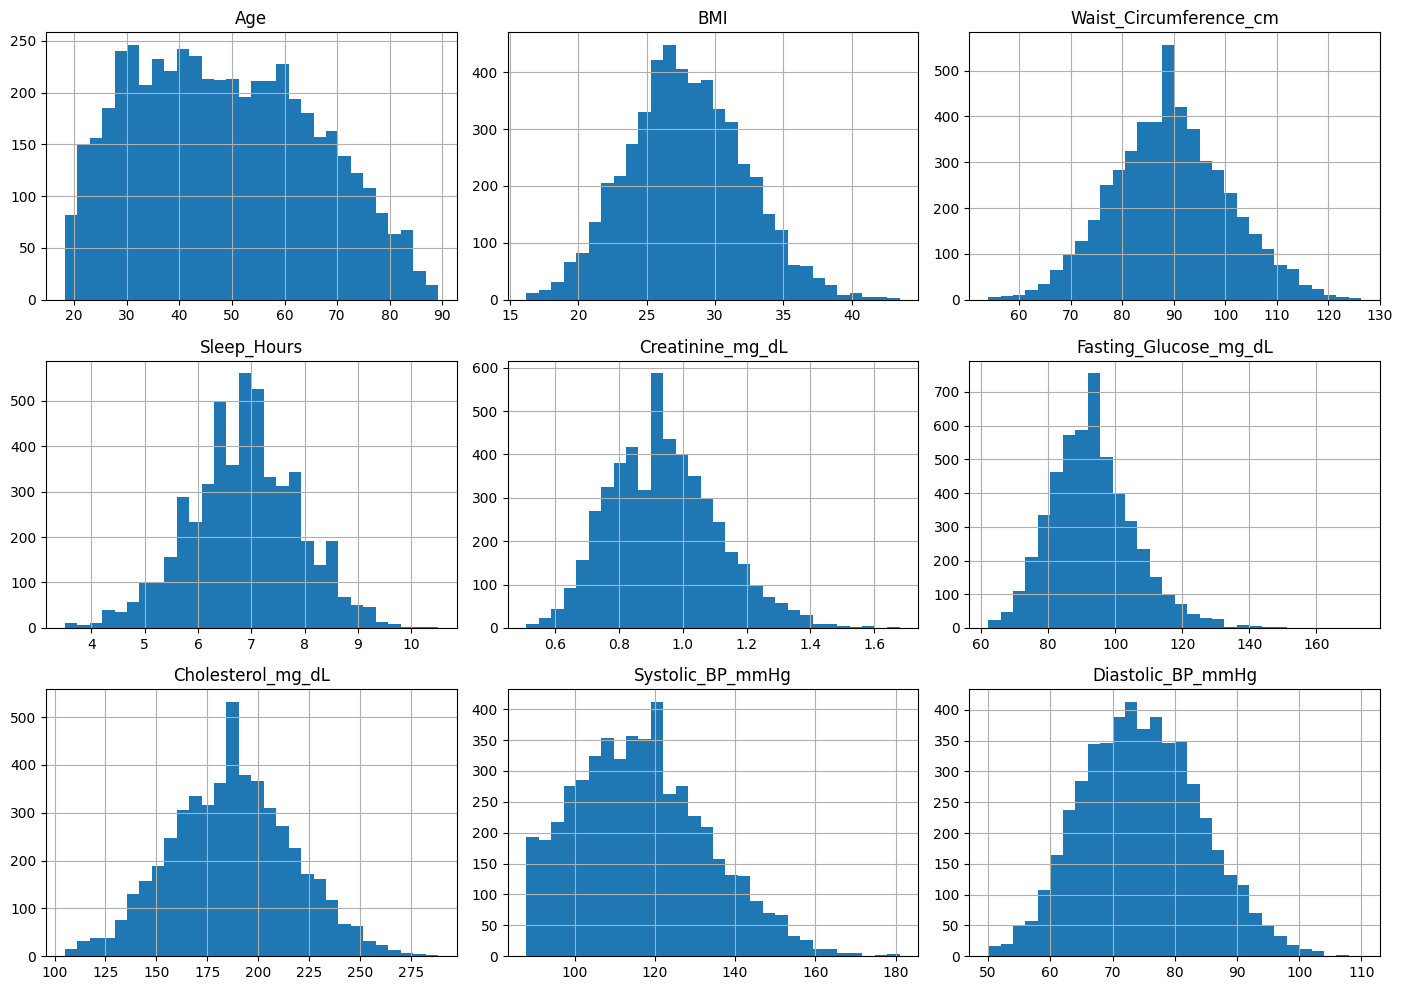

Age                       0.21
BMI                       0.17
Waist_Circumference_cm    0.10
Sleep_Hours              -0.08
Creatinine_mg_dL          0.43
Fasting_Glucose_mg_dL     0.65
Cholesterol_mg_dL         0.06
Systolic_BP_mmHg          0.48
Diastolic_BP_mmHg         0.20
dtype: float64


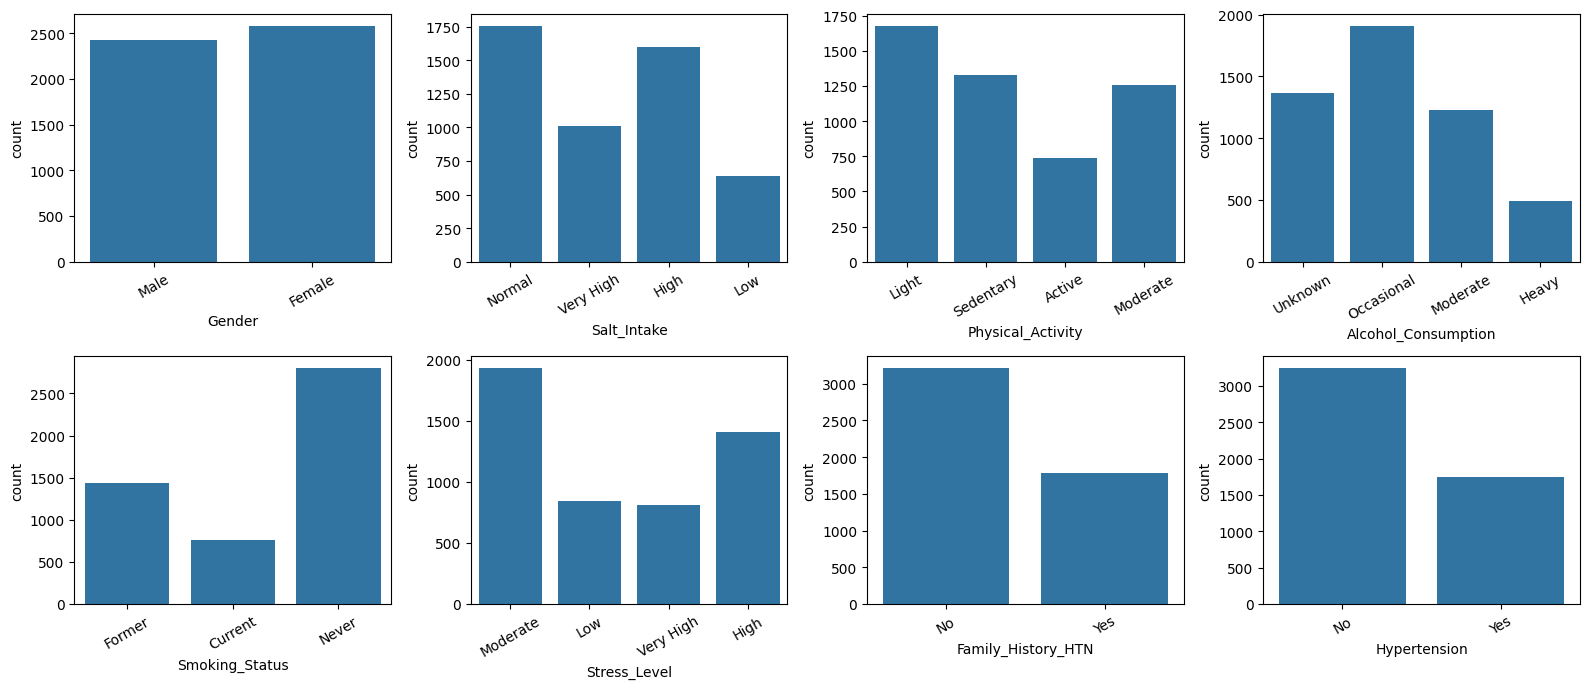

In [159]:
df[num_cols].hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()
print(df[num_cols].skew().round(2))


cols = cat_cols + ["Hypertension"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

From my figures above obtained from my cleaned dataset of 5,000 rows, the first is a grid of histograms for the numeric variables and the other is a grid of bar charts for the categorical variables. The skew values are printed as text between them.

**ANALYSIS FOR THE HISTOGRAMS FOR THE NUMERIC VARIANCE**